# AgentAccess for Dallas Parks

**Authors:** Alexander Michels

This notebook walks through the a generalized Agent-Based Model for spatial accessibility analysis using parks in Dallas County, TX. **This is not intended to be a case study, but rather a demonstration of the method.**

In [1]:
import access
import geopandas as gpd
from IPython.display import Image
import math
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from tqdm import tqdm
import sys
sys.path.append("../")
from agentaccess.Model import AgentAccess
# pandas gives warnings too often
pd.options.mode.chained_assignment = None

In [2]:
figsize=(10,10)

1553


,STATEFP,COUNTYFP,TRACTCE,BLKGRPCE,GEOID,NAMELSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,TOTPOP,geometry
0,48,113,013901,2,481130139012,Block Group 2,G5030,S,1241037,0,+32.9299867,-096.8970941,1632.0,"POLYGON ((-96.90265 32.93862, -96.90255 32.938..."
1,48,113,000300,1,481130003001,Block Group 1,G5030,S,585736,0,+32.8297631,-096.7723315,1787.0,"POLYGON ((-96.77472 32.82549, -96.77472 32.826..."
2,48,113,006402,2,481130064022,Block Group 2,G5030,S,776895,0,+32.7273756,-096.8715321,2369.0,"POLYGON ((-96.87425 32.72733, -96.87423 32.728..."
3,48,113,016522,1,481130165221,Block Group 1,G5030,S,3162233,0,+32.5985453,-096.9485640,2612.0,"POLYGON ((-96.95888 32.59957, -96.95886 32.599..."
4,48,113,020100,1,481130201001,Block Group 1,G5030,S,9352391,145040,+32.8330215,-096.9037936,1011.0,"POLYGON ((-96.92181 32.81443, -96.9218 32.8147..."


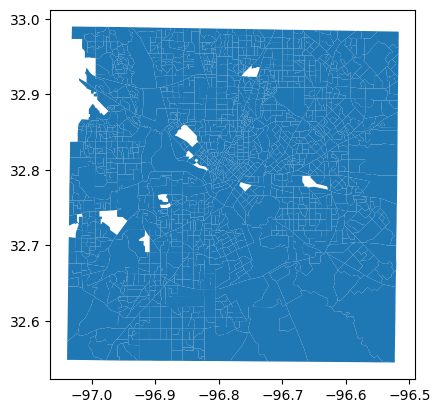

In [3]:
pop = gpd.read_file("../data/dallas_example/DallasBlockGroups.gpkg")
pop = pop[pop["TOTPOP"] > 0]
pop = pop.to_crs("EPSG:4326")
pop.plot()
print(len(pop))
pop.head()

,:id,:version,:created_at,:updated_at,objectid,address,park_type,owned_by,maintenanc,park_name,greenbelt,geometry
0,row-gydu-xbmz-nvn3,rv-mr9m_uzz4~w26z,2026-03-12 14:50:51.186000+00:00,2026-03-12 14:50:51.186000+00:00,840294,701 YOUNG ST,SPECIAL (DOWNTOWN),PARK,3,LUBBEN PLAZA,NaN,"MULTIPOLYGON (((-96.80519 32.77629, -96.80528 ..."
1,row-ckme-6dce-22az,rv-7rvs~sbku_dqya,2026-03-12 14:50:51.186000+00:00,2026-03-12 14:50:51.186000+00:00,840254,6401 GASTON AVE,SPECIAL,PARK,1,HARRELL,NaN,"MULTIPOLYGON (((-96.75274 32.81405, -96.75276 ..."
2,row-dkzp.5gy7~kfes,rv-gttz-r9xt_ahdz,2026-03-12 14:50:51.186000+00:00,2026-03-12 14:50:51.186000+00:00,840272,3212 N WINNETKA AVE,COMMUNITY,PARK,5,HATTIE R MOORE,NaN,"MULTIPOLYGON (((-96.83967 32.78132, -96.83943 ..."
3,row-y3b7-ed9q.sqmz,rv-yp9m-a67h.bcxh,2026-03-12 14:50:51.186000+00:00,2026-03-12 14:50:51.186000+00:00,840421,300 W WHEATLAND RD,COMMUNITY,PARK,4,DANIELDALE,NaN,"MULTIPOLYGON (((-96.83104 32.6474, -96.83068 3..."
4,row-cvju-ip2y-6w9r,rv-9s3u~essw.5j5a,2026-03-12 14:50:51.186000+00:00,2026-03-12 14:50:51.186000+00:00,840324,1919 2ND AVE,SPECIAL (OCA),PARK,3,SOUTH DALLAS CULTURAL CENTER,NaN,"MULTIPOLYGON (((-96.75644 32.77114, -96.75675 ..."


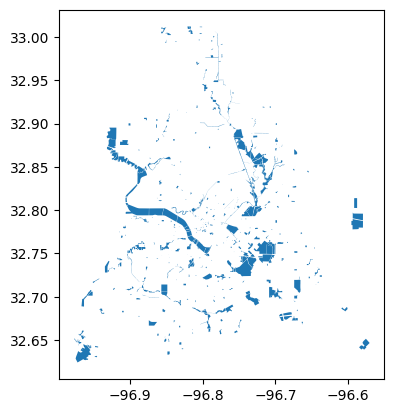

In [4]:
# park data from Dallas OpenData portal: https://www.dallasopendata.com/dataset/Parks/9e6m-eru6 
parks = gpd.read_file("../data/dallas_example/Parks_20260904.geojson")
parks.plot()
parks.head()

In [5]:
# project data to calculate Euclidean distance
CRS = "EPSG:3083"  # Texas Albers Equal Area
pop = pop.to_crs(CRS)
popcentr = pop.copy()
popcentr.geometry = popcentr.geometry.centroid
parks = parks.to_crs(CRS)
parks["Area"] = parks.area
parks.geometry = parks.geometry.centroid

In [6]:
parks.head()

,:id,:version,:created_at,:updated_at,objectid,address,park_type,owned_by,maintenanc,park_name,greenbelt,geometry,Area
0,row-gydu-xbmz-nvn3,rv-mr9m_uzz4~w26z,2026-03-12 14:50:51.186000+00:00,2026-03-12 14:50:51.186000+00:00,840294,701 YOUNG ST,SPECIAL (DOWNTOWN),PARK,3,LUBBEN PLAZA,NaN,POINT (1798755.132 7632783.743),3346.993598
1,row-ckme-6dce-22az,rv-7rvs~sbku_dqya,2026-03-12 14:50:51.186000+00:00,2026-03-12 14:50:51.186000+00:00,840254,6401 GASTON AVE,SPECIAL,PARK,1,HARRELL,NaN,POINT (1803525.875 7637121.17),1561.063609
2,row-dkzp.5gy7~kfes,rv-gttz-r9xt_ahdz,2026-03-12 14:50:51.186000+00:00,2026-03-12 14:50:51.186000+00:00,840272,3212 N WINNETKA AVE,COMMUNITY,PARK,5,HATTIE R MOORE,NaN,POINT (1795565.817 7633113.855),13643.239031
3,row-y3b7-ed9q.sqmz,rv-yp9m-a67h.bcxh,2026-03-12 14:50:51.186000+00:00,2026-03-12 14:50:51.186000+00:00,840421,300 W WHEATLAND RD,COMMUNITY,PARK,4,DANIELDALE,NaN,POINT (1796754.535 7618210.095),75624.884818
4,row-cvju-ip2y-6w9r,rv-9s3u~essw.5j5a,2026-03-12 14:50:51.186000+00:00,2026-03-12 14:50:51.186000+00:00,840324,1919 2ND AVE,SPECIAL (OCA),PARK,3,SOUTH DALLAS CULTURAL CENTER,NaN,POINT (1803239.099 7632316.766),8316.507470


<Axes: >

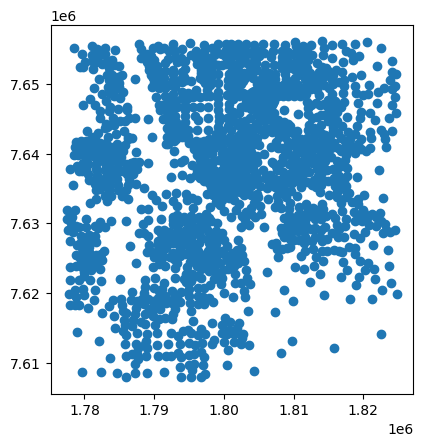

In [7]:
popcentr.plot()

<Axes: >

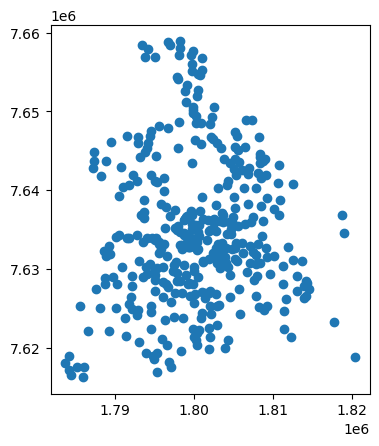

In [8]:
parks.plot()

In [9]:
# calculate Euclidean distances
# based on: https://pysal.org/access/_modules/access/access.html#Access.create_euclidean_distance
# get the cartesian product by mergining on a dummy column
popcentr["temp"] = 1
joined = popcentr[["temp", "geometry", "GEOID"]].rename(columns={"GEOID": "origin"}).merge(popcentr[["temp", "geometry", "GEOID"]].rename(columns={"geometry": "geomb", "GEOID": "destination"}))
joined.drop("temp", inplace=True, axis=1)  # drop dummy column
joined["euclidean"] = joined.distance(joined.set_geometry("geomb"))  # calculate distances
joined.drop(columns=["geometry", "geomb"], inplace=True)
joined.head()

,origin,destination,euclidean
0,481130139012,481130139012,0.000000
1,481130139012,481130003001,16118.681508
2,481130139012,481130064022,22636.413914
3,481130139012,481130165221,37136.969881
4,481130139012,481130201001,10952.482925


## Model

The model executes across a number of time steps set by the user.

In [10]:
time_steps = 10

In [11]:
# intialize our model
model = AgentAccess(
    pop,
    "GEOID",
    "TOTPOP",
    parks,
    "objectid",
    "Area",
    joined,
    "origin",
    "destination",
    "euclidean",
    time_steps,
    pop_per_agent=100,
    output_path="../outputs/",
    processes=16,
    addl_cost_params= {"tau": {"distribution": "constant", "value": 1000}}
)

In [12]:
model.run_model()

Running Model: 100%|███████████████████████████████████████| 10/10 [1:00:37<00:00, 363.72s/it]


In [13]:
model.save_gif()

Let's view the gif from the model!

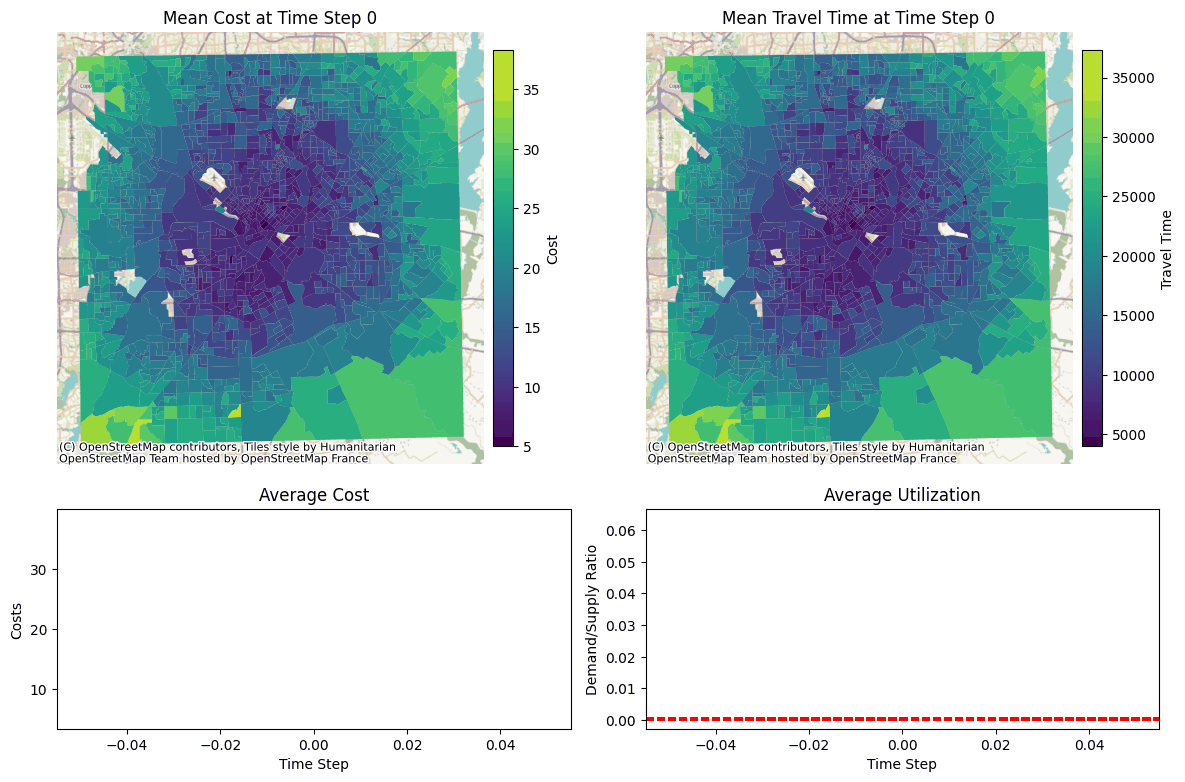

In [14]:
Image(filename=os.path.join(model.output_dir, "movie.gif"))

We can also inspect all of the internal data that our model generated:

In [15]:
model.cost_df.head()

euclidean
origin       destination               
481130139012 481130201001  10952.482925
             481130165111  33732.950877
             481130087031  27319.005785
             481130127013  22474.163428
             481130085002  25890.402728

In [16]:
model.demand_df.head()

,ID,GEOID,Cost Field,tau,Choice 0,Cost 0,Choice 1,Cost 1,Choice 2,Cost 2,...,Choice 5,Cost 5,Choice 6,Cost 6,Choice 7,Cost 7,Choice 8,Cost 8,Choice 9,Cost 9
0,0,481130139012,euclidean,1000,481130076051,10.229085,481130131011,11.756609,481130004072,15.707967,...,481130037002,40.100373,481130017032,17.889749,481130069001,84.045026,481130192122,200.819779,481130064021,31.979457
1,1,481130139012,euclidean,1000,481130068001,20.878114,481130131061,44.280904,481130059013,28.607014,...,481130078213,20.971850,481130167101,39.346604,481130113003,29.745906,481130096111,3.856365,481130106012,15.835155
2,2,481130139012,euclidean,1000,481130190191,18.046030,481130130081,20.423536,481130190181,22.896773,...,481130096111,3.847715,481130097021,6.921477,481130171013,39.551780,481130079032,19.246311,481130025002,25.206328
3,3,481130139012,euclidean,1000,481130185063,20.185385,481130027031,51.973837,481130142091,9.025227,...,481130129001,22.455167,481130046001,41.844796,481130130072,20.386975,481130054002,27.423294,481130080002,20.277427
4,4,481130139012,euclidean,1000,481130142091,8.885443,481130124001,22.873834,481130130072,20.291819,...,481130204012,21.494283,481130067021,23.709868,481130027031,61.147771,481130096111,3.856365,481130108053,24.755296


In [17]:
model.supply_df.head()

,geometry,Supply,Demand 0,D/S Ratio 0,Demand 1,D/S Ratio 1,Demand 2,D/S Ratio 2,Demand 3,D/S Ratio 3,...,Demand 5,D/S Ratio 5,Demand 6,D/S Ratio 6,Demand 7,D/S Ratio 7,Demand 8,D/S Ratio 8,Demand 9,D/S Ratio 9
GEOID,,,,,,,,,,,,,,,,,,,,,
481130001001,"POLYGON ((1804851.863 7637967.654, 1805053.408...",39904.728245,101,0.002531,97,0.002431,79,0.001980,101,0.002531,...,98,0.002456,112,0.002807,103,0.002581,93,0.002331,101,0.002531
481130002013,"POLYGON ((1802638.041 7638816.925, 1802703.584...",33612.325150,116,0.003451,173,0.005147,208,0.006188,211,0.006277,...,205,0.006099,227,0.006753,207,0.006158,198,0.005891,212,0.006307
481130003004,"POLYGON ((1800736 7638773.99, 1800762.169 7638...",53810.720917,103,0.001914,23,0.000427,60,0.001115,57,0.001059,...,80,0.001487,66,0.001227,76,0.001412,88,0.001635,73,0.001357
481130004052,"POLYGON ((1796740.01 7636842.204, 1796790.955 ...",5474.993728,106,0.019361,81,0.014795,101,0.018448,104,0.018995,...,104,0.018995,116,0.021187,124,0.022648,116,0.021187,100,0.018265
481130004072,"POLYGON ((1795774.602 7637764.397, 1795797.274...",8223.830774,136,0.016537,177,0.021523,169,0.020550,174,0.021158,...,151,0.018361,177,0.021523,184,0.022374,172,0.020915,181,0.022009


In [18]:
model.spatial_units_df.head()

,Demand,geometry,Cost 0,D/S Ratio 0,Time 0,Cost 1,D/S Ratio 1,Time 1,Cost 2,D/S Ratio 2,...,Time 6,Cost 7,D/S Ratio 7,Time 7,Cost 8,D/S Ratio 8,Time 8,Cost 9,D/S Ratio 9,Time 9
GEOID,,,,,,,,,,,,,,,,,,,,,
481130139012,1632.0,"POLYGON ((1789118.822 7650513.669, 1789128.3 7...",18.209180,0.003870,17209.079838,29.649881,0.023458,21289.419845,23.732452,0.010202,...,15669.539422,32.447504,0.015365,23544.162882,32.176951,0.008993,16926.966995,22.076594,0.004178,16935.445526
481130003001,1787.0,"POLYGON ((1801423.099 7638291.947, 1801420.523...",10.022592,0.007830,9022.491874,16.877540,0.010256,9220.620664,21.520570,0.012228,...,8940.450896,14.905476,0.003260,9726.065175,11.484733,0.011557,7470.228705,15.257425,0.008384,8231.881860
481130064022,2369.0,"POLYGON ((1792431.74 7627124.162, 1792431.173 ...",7.497214,0.012778,6497.113986,14.444470,0.007825,9263.220178,13.774021,0.011422,...,9779.340984,16.802384,0.013226,10807.434471,18.157330,0.009382,9615.272587,22.034306,0.007446,10182.562104
481130165221,2612.0,"POLYGON ((1784906.306 7612714.107, 1784907.385...",24.028562,0.007443,23028.461634,29.131771,0.022868,22560.980913,30.301336,0.004231,...,26822.823283,27.145434,0.002437,20069.426809,26.641924,0.002727,23323.295028,27.719038,0.004337,21645.733182
481130201001,1011.0,"POLYGON ((1787714.098 7636672.641, 1787713.969...",13.703203,0.005480,12703.102659,19.928513,0.005734,13029.799247,18.765749,0.004266,...,13844.795397,23.700041,0.004360,16044.069941,22.950718,0.004607,15401.814902,22.964125,0.004617,15401.814902


In [19]:
def normalize_columns(df, columns, to_flip=[]):
    for column in columns:
        df[column] = (df[column] - df[column].min()) / (df[column].max() - df[column].min())
        if column in to_flip:
            df[column] = 1 - df[column]
    return df

def average_columns(df, new_column, columns_to_average):
    df[new_column] = df[columns_to_average].mean(axis=1)
    return df

ABMs have some randomness, so to account for this, we will take averages over the last half of the time steps:

In [20]:
last_portion = 2
df = average_columns(model.spatial_units_df, "D/S Ratio", [f"D/S Ratio {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = average_columns(df, "Time", [f"Time {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = average_columns(df, "Cost", [f"Cost {x}" for x  in range(time_steps - (time_steps//last_portion), time_steps)])
df = df[["D/S Ratio", "Time", "Cost", "geometry"]]
df.head()

,D/S Ratio,Time,Cost,geometry
GEOID,,,,
481130139012,0.015191,17807.397969,26.379549,"POLYGON ((1789118.822 7650513.669, 1789128.3 7..."
481130003001,0.010524,8693.641323,13.696963,"POLYGON ((1801423.099 7638291.947, 1801420.523..."
481130064022,0.009252,10245.176089,17.994691,"POLYGON ((1792431.74 7627124.162, 1792431.173 ..."
481130165221,0.007224,23241.106644,29.192571,"POLYGON ((1784906.306 7612714.107, 1784907.385..."
481130201001,0.004893,15168.645876,22.477645,"POLYGON ((1787714.098 7636672.641, 1787713.969..."


In [21]:
cols = ["D/S Ratio", "Time", "Cost"]
model_result = df
# model_result = normalize_columns(df, columns=cols)
model_result.head()

,D/S Ratio,Time,Cost,geometry
GEOID,,,,
481130139012,0.015191,17807.397969,26.379549,"POLYGON ((1789118.822 7650513.669, 1789128.3 7..."
481130003001,0.010524,8693.641323,13.696963,"POLYGON ((1801423.099 7638291.947, 1801420.523..."
481130064022,0.009252,10245.176089,17.994691,"POLYGON ((1792431.74 7627124.162, 1792431.173 ..."
481130165221,0.007224,23241.106644,29.192571,"POLYGON ((1784906.306 7612714.107, 1784907.385..."
481130201001,0.004893,15168.645876,22.477645,"POLYGON ((1787714.098 7636672.641, 1787713.969..."


<Axes: >

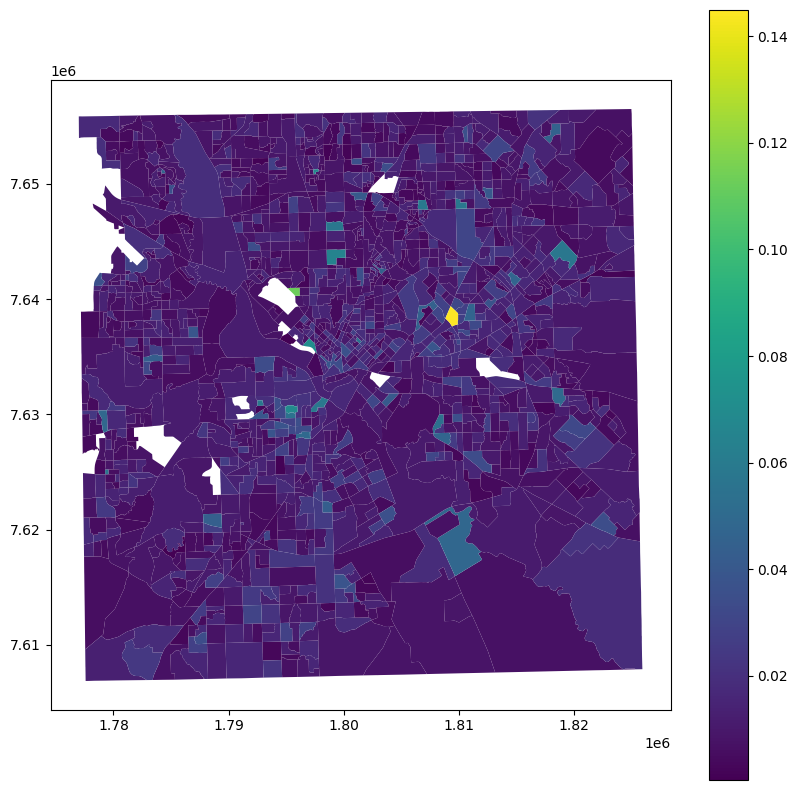

In [22]:
model_result.plot(column="D/S Ratio", figsize=figsize, legend=True)

<Axes: >

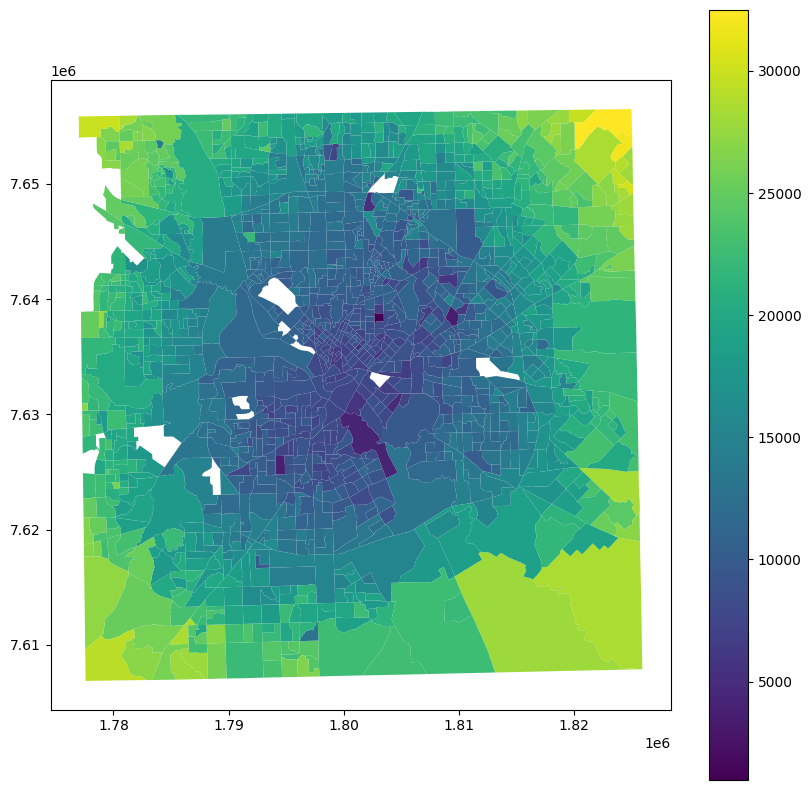

In [23]:
model_result.plot(column="Time", figsize=figsize, legend=True)

<Axes: >

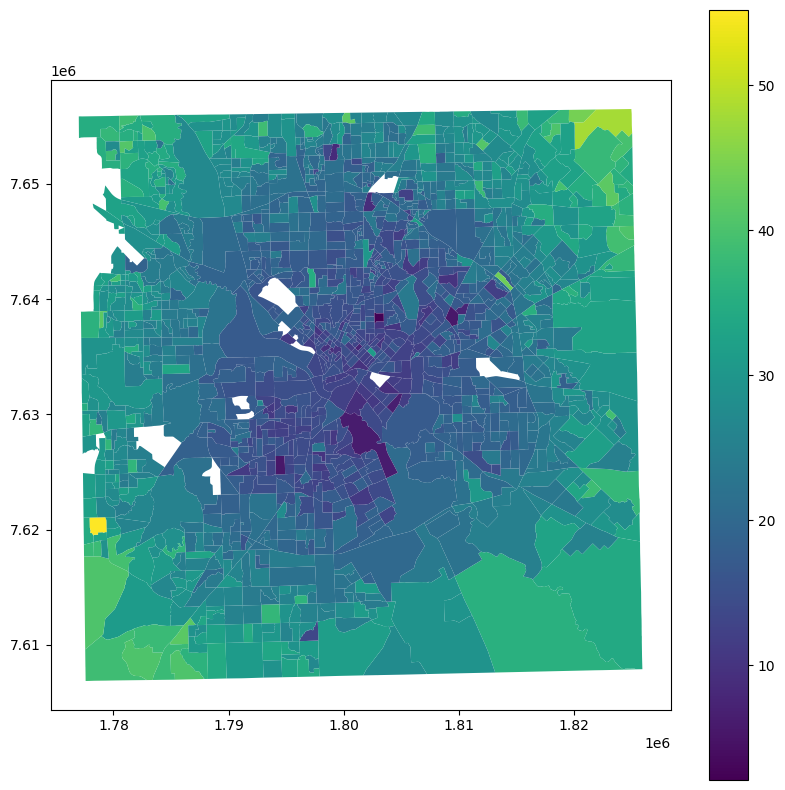

In [24]:
model_result.plot(column="Cost", figsize=figsize, legend=True)

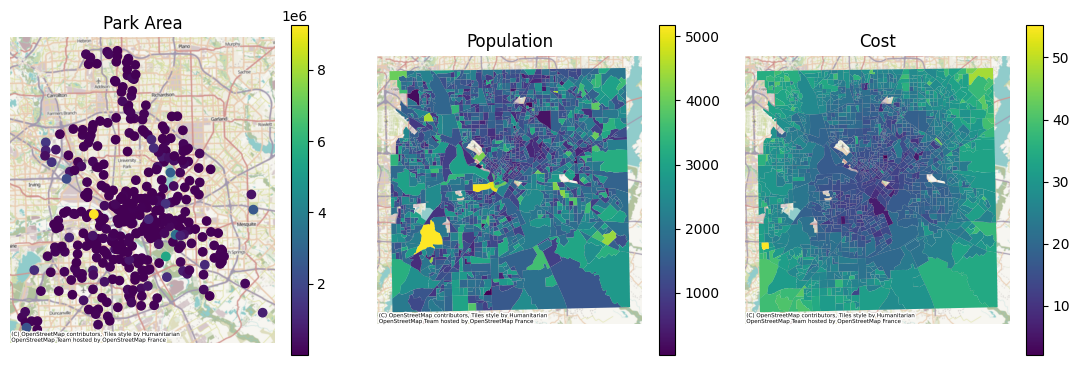

In [25]:
import contextily as cx
fig, axes = plt.subplots(nrows=1, ncols=3,figsize=(11,3.75))
parks.plot(column='Area', legend=True, ax=axes[0])
pop.plot(column="TOTPOP", legend=True, ax=axes[1])
model_result.plot(column="Cost", ax=axes[2], legend=True)
for ax, gdf, title in zip(axes, [parks, pop, model_result], ["Park Area", "Population", "Cost"]):
    cx.add_basemap(ax=ax, crs=gdf.crs.to_string(), attribution_size=4)
    ax.axis('off')
    ax.set_title(title)
fig.tight_layout()
plt.savefig("../examples/ParkOverview.png")